# Computer Vision Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Dua e Zainab  |  **Reg No:** FA34-BAI-027

| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits (027) | **27** |
| HOG cell size | last digit 7 is odd | **16 x 16** |
| SIFT grid size | last digit 7 is in 5 to 9 | **6 x 6 (36 keypoints)** |

In [1]:
!pip install -q medmnist opencv-python scikit-image scikit-learn matplotlib pandas

import random, numpy as np, cv2, pandas as pd, matplotlib.pyplot as plt
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

REG_NO   = "FA34-BAI-027"
SEED     = 27          # last two digits
HOG_CELL = 16          # last digit 7 is odd -> 16x16
GRID_N   = 6           # last digit 7 is in 5-9 -> 6x6 grid (36 keypoints)
CLASSES  = [1, 5, 6, 7]
NAMES    = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_TR, N_VA, N_TE = 100, 30, 30

random.seed(SEED); np.random.seed(SEED)
print(f"Reg {REG_NO} | seed={SEED} | HOG cell={HOG_CELL}x{HOG_CELL} | SIFT grid={GRID_N}x{GRID_N} ({GRID_N**2} keypoints)")

Reg FA34-BAI-027 | seed=27 | HOG cell=16x16 | SIFT grid=6x6 (36 keypoints)


# Q1. Data setup

100%|██████████| 156M/156M [02:44<00:00, 950kB/s] 


Train X shape=(400, 128, 128) y shape=(400,) class counts={'eosinophil': np.int64(100), 'monocyte': np.int64(100), 'neutrophil': np.int64(100), 'platelet': np.int64(100)}
Val   X shape=(120, 128, 128) y shape=(120,) class counts={'eosinophil': np.int64(30), 'monocyte': np.int64(30), 'neutrophil': np.int64(30), 'platelet': np.int64(30)}
Test  X shape=(120, 128, 128) y shape=(120,) class counts={'eosinophil': np.int64(30), 'monocyte': np.int64(30), 'neutrophil': np.int64(30), 'platelet': np.int64(30)}


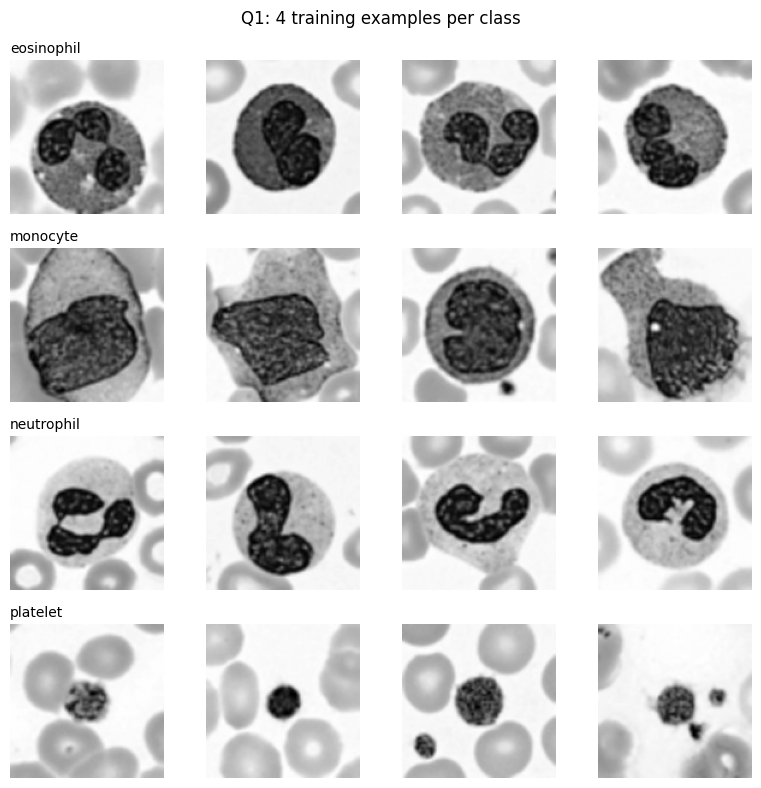

In [2]:
rng = np.random.RandomState(SEED)

def make_split(split, per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs, labels = ds.imgs, ds.labels.ravel()
    X, y = [], []
    for new_lbl, c in enumerate(CLASSES):
        idx = rng.choice(np.where(labels == c)[0], per_class, replace=False)
        for i in idx:
            g = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)                 # grayscale
            g = cv2.resize(g, (128, 128), interpolation=cv2.INTER_CUBIC)  # 128x128
            X.append(g); y.append(new_lbl)
    return np.array(X, dtype=np.uint8), np.array(y)

X_tr, y_tr = make_split("train", N_TR)
X_va, y_va = make_split("val",   N_VA)
X_te, y_te = make_split("test",  N_TE)

for n, X, y in [("Train", X_tr, y_tr), ("Val", X_va, y_va), ("Test", X_te, y_te)]:
    print(f"{n:5s} X shape={X.shape} y shape={y.shape} class counts={dict(zip(NAMES, np.bincount(y)))}")

fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(y_tr == r)[0][:4]
    for c in range(4):
        ax[r, c].imshow(X_tr[idx[c]], cmap="gray"); ax[r, c].axis("off")
        if c == 0: ax[r, c].set_title(NAMES[r], loc="left", fontsize=10)
plt.suptitle("Q1: 4 training examples per class"); plt.tight_layout(); plt.show()

# Q2. HOG + SVM

**HOG feature length (by hand)**
- Image 128 x 128, cell 16 x 16 -> 128/16 = 8 cells per side (8 x 8 cells)
- Block = 2 x 2 cells, stride 1 cell -> 8 - 2 + 1 = 7 blocks per side -> 7 x 7 = 49 blocks
- Each block = 2 x 2 cells x 9 orientations = 36 values
- Total = 49 x 36 = **1764**

HOG feature length: 1764 | train: (400, 1764) | val: (120, 1764)


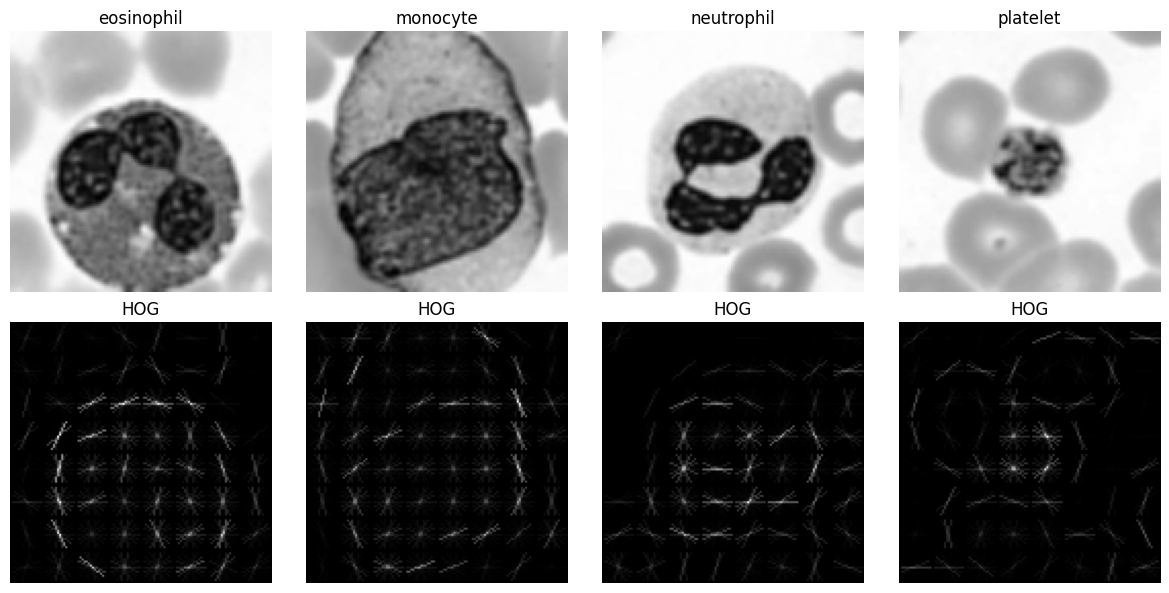

In [9]:
def hog_feat(img, vis=False):
    return hog(img.astype(np.float32) / 255.0, orientations=9,
               pixels_per_cell=(HOG_CELL, HOG_CELL), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True, visualize=vis)

def hog_batch(X): return np.array([hog_feat(i) for i in X])

Htr, Hva = hog_batch(X_tr), hog_batch(X_va)
print("HOG feature length:", Htr.shape[1], "| train:", Htr.shape, "| val:", Hva.shape)
assert Htr.shape[1] == 49 * 36 == 1764

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for r in range(4):
    img = X_tr[np.where(y_tr == r)[0][0]]
    _, himg = hog_feat(img, vis=True)
    ax[0, r].imshow(img, cmap="gray"); ax[0, r].set_title(NAMES[r]); ax[0, r].axis("off")
    ax[1, r].imshow(himg, cmap="gray"); ax[1, r].set_title("HOG"); ax[1, r].axis("off")
plt.tight_layout(); plt.show()

   C  val_acc  val_macroF1
 0.1    0.725     0.724324
 1.0    0.725     0.723922
10.0    0.725     0.723922

[HOG+SVM] best C=0.1 | val accuracy=0.7250 | val macro-F1=0.7243
Confusion matrix (rows=true, cols=pred):
 [[15 10  5  0]
 [ 5 22  3  0]
 [ 6  3 21  0]
 [ 0  1  0 29]]


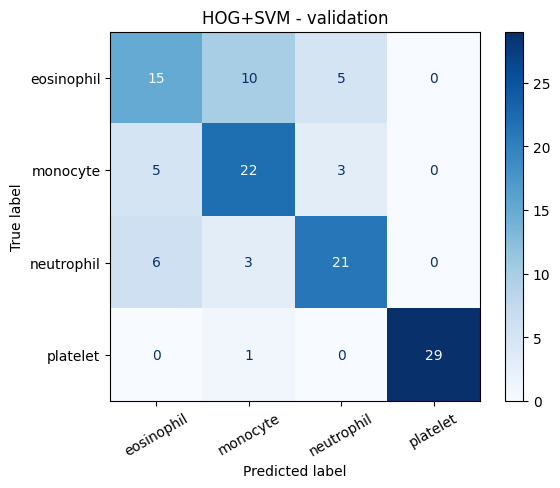

In [10]:
def train_svm(Ftr, ytr, Fva, yva, tag):
    best, rows = None, []
    for C in [0.1, 1, 10]:
        m = make_pipeline(StandardScaler(),
                          LinearSVC(C=C, dual=True, max_iter=50000, random_state=SEED))
        m.fit(Ftr, ytr)
        p = m.predict(Fva)
        acc, f1 = accuracy_score(yva, p), f1_score(yva, p, average="macro")
        rows.append((C, acc, f1))
        if best is None or acc > best[1]:          # ties keep the smaller C
            best = (C, acc, f1, m, p)
    print(pd.DataFrame(rows, columns=["C", "val_acc", "val_macroF1"]).to_string(index=False))
    C, acc, f1, m, p = best
    print(f"\n[{tag}] best C={C} | val accuracy={acc:.4f} | val macro-F1={f1:.4f}")
    cm = confusion_matrix(yva, p)
    print("Confusion matrix (rows=true, cols=pred):\n", cm)
    ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{tag} - validation"); plt.show()
    return m, cm

hog_model, cm_hog = train_svm(Htr, y_tr, Hva, y_va, "HOG+SVM")

# Q3. SIFT + SVM

Keypoints/image -> average=110.4, min=19, max=358
Images with zero keypoints: 0


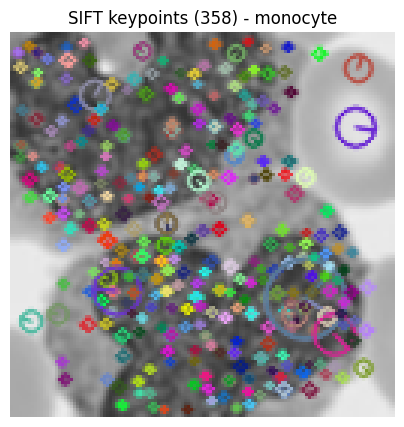

In [11]:
sift = cv2.SIFT_create()
counts = []
for img in X_tr:
    kp, _ = sift.detectAndCompute(img, None)
    counts.append(len(kp))
counts = np.array(counts)
print(f"Keypoints/image -> average={counts.mean():.1f}, min={counts.min()}, max={counts.max()}")
print("Images with zero keypoints:", int((counts == 0).sum()))

i = int(np.argmax(counts))
kp, _ = sift.detectAndCompute(X_tr[i], None)
plt.figure(figsize=(5, 5))
plt.imshow(cv2.drawKeypoints(X_tr[i], kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS), cmap="gray")
plt.title(f"SIFT keypoints ({len(kp)}) - {NAMES[y_tr[i]]}"); plt.axis("off"); plt.show()

**Why a different number of keypoints is a problem:** Each keypoint gives a 128-value descriptor, so an image with more keypoints gives a longer feature vector, and an SVM needs every sample to have the same fixed length.

**SIFT grid feature length (by hand)**
- Grid 6 x 6 = 36 grid points, each with one 128-value SIFT descriptor (keypoint size 32)
- Total = 36 x 128 = **4608**

SIFT feature length: 4608 | train: (400, 4608) | val: (120, 4608)
   C  val_acc  val_macroF1
 0.1     0.75     0.747902
 1.0     0.75     0.747902
10.0     0.75     0.747902

[SIFT+SVM] best C=0.1 | val accuracy=0.7500 | val macro-F1=0.7479
Confusion matrix (rows=true, cols=pred):
 [[15 11  3  1]
 [ 7 21  2  0]
 [ 3  2 25  0]
 [ 0  1  0 29]]


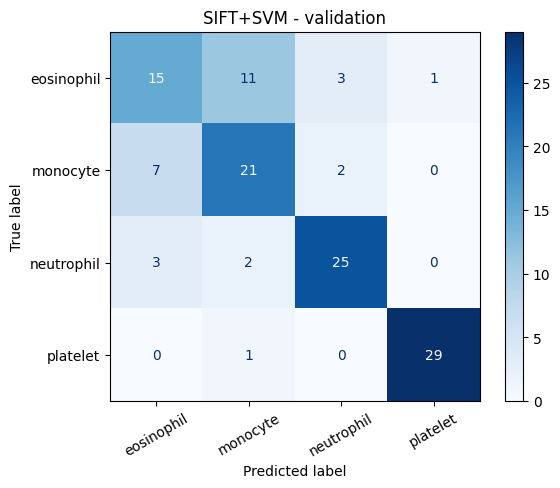

In [12]:
step = 128 / GRID_N
centers = [(j + 0.5) * step for j in range(GRID_N)]          # evenly spread over 128x128
def grid_kps():
    return [cv2.KeyPoint(float(x), float(y), 32, 0) for y in centers for x in centers]

def sift_feat(img):
    _, des = sift.compute(img, grid_kps())
    assert des.shape == (GRID_N**2, 128), des.shape
    return des.flatten()

def sift_batch(X): return np.array([sift_feat(i) for i in X])

Str, Sva = sift_batch(X_tr), sift_batch(X_va)
print("SIFT feature length:", Str.shape[1], "| train:", Str.shape, "| val:", Sva.shape)
assert Str.shape[1] == 36 * 128 == 4608

sift_model, cm_sift = train_svm(Str, y_tr, Sva, y_va, "SIFT+SVM")

# Q4. Robustness

**Prediction (made before running anything)**
- **Rotation:** I think HOG will lose more accuracy, because its features are tied to fixed gradient directions and cell positions, so a 20 degree turn changes the orientation histograms. (SIFT grid descriptors also assume upright keypoints, so it may drop too.)
- **Noise:** I think HOG will lose more accuracy, because it takes raw pixel gradients with no smoothing, and noise creates many false gradients. SIFT blurs the image first (Gaussian), which suppresses noise.

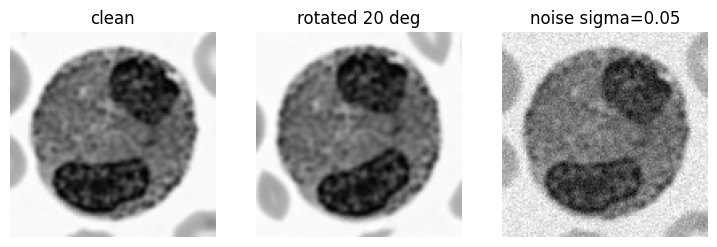

            Clean accuracy  Rotated accuracy  Noisy accuracy  Rotation drop  \
HOG + SVM           0.6333             0.675          0.2500        -0.0417   
SIFT + SVM          0.7000             0.675          0.7333         0.0250   

            Noise drop  
HOG + SVM       0.3833  
SIFT + SVM     -0.0333  

HOG + SVM test confusion matrix (clean):
 [[12  7 11  0]
 [ 9 17  4  0]
 [ 7  6 17  0]
 [ 0  0  0 30]]

SIFT + SVM test confusion matrix (clean):
 [[17  7  6  0]
 [ 6 20  3  1]
 [ 9  2 17  2]
 [ 0  0  0 30]]


In [13]:
def rotate(img, ang=20):
    M = cv2.getRotationMatrix2D((128 / 2, 128 / 2), ang, 1.0)
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT_101)

noise_rng = np.random.RandomState(SEED)
def add_noise(X, sigma=0.05):
    n = np.clip(X / 255.0 + noise_rng.normal(0, sigma, X.shape), 0, 1)   # image scaled to 0-1
    return np.round(n * 255).astype(np.uint8)

X_rot   = np.array([rotate(i) for i in X_te])
X_noisy = add_noise(X_te)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax, [X_te[0], X_rot[0], X_noisy[0]], ["clean", "rotated 20 deg", "noise sigma=0.05"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()

res = {}
for name, model, fx in [("HOG + SVM", hog_model, hog_batch), ("SIFT + SVM", sift_model, sift_batch)]:
    res[name] = [accuracy_score(y_te, model.predict(fx(X))) for X in (X_te, X_rot, X_noisy)]

table = pd.DataFrame(res, index=["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]).T.round(4)
table["Rotation drop"] = (table["Clean accuracy"] - table["Rotated accuracy"]).round(4)
table["Noise drop"]    = (table["Clean accuracy"] - table["Noisy accuracy"]).round(4)
print(table)

for name, model, fx in [("HOG + SVM", hog_model, hog_batch), ("SIFT + SVM", sift_model, sift_batch)]:
    print(f"\n{name} test confusion matrix (clean):\n", confusion_matrix(y_te, model.predict(fx(X_te))))

**Was my prediction correct?**

_Replace with 3 sentences from your table above:_ My prediction was [correct / partly correct / wrong]. In the table, HOG dropped from X to Y under rotation and from X to Z under noise, while SIFT dropped from A to B under rotation and from A to C under noise. So [model] lost more under rotation and [model] lost more under noise, because [reason linked to your numbers].

# Q5. Short answers and AI log

In [14]:
def top_confused(cm):
    best = (0, None)
    for a in range(4):
        for b in range(a + 1, 4):
            s = cm[a, b] + cm[b, a]
            if s > best[0]: best = (s, (NAMES[a], NAMES[b]))
    return best
print("HOG  most confused pair (validation):", top_confused(cm_hog))
print("SIFT most confused pair (validation):", top_confused(cm_sift))

HOG  most confused pair (validation): (np.int64(15), ('eosinophil', 'monocyte'))
SIFT most confused pair (validation): (np.int64(18), ('eosinophil', 'monocyte'))


**(a) Block normalisation:** Gradient magnitudes change with lighting and contrast. HOG normalises each block of cells so the descriptor depends on local gradient shape, not brightness, which makes it more robust to illumination.

**(b) Choosing C on the test set:** The test set must act as unseen data. If I pick C by test accuracy, the test set influences the model, so the reported score is optimistic (data leakage) and does not estimate real performance. C must be chosen on the validation set.

**Most confused classes:** [fill from the output above, e.g. neutrophil and eosinophil]. Grayscale removes stain colour (eosinophil granules are reddish and nuclei are purple), and in grayscale their shape and texture look similar.

**AI log**

| Prompt (one line) | What I changed | How I checked |
|---|---|---|
| "Code for HOG vs SIFT + LinearSVC on BloodMNIST, seed 27, HOG cell 16, 6x6 SIFT grid" | Set my reg-no settings, added StandardScaler and C selection on validation | Printed shapes, feature lengths 1764 and 4608 (matched hand calculation), plotted HOG and keypoint pictures |